<a href="https://colab.research.google.com/github/nadayali710-spec/Programming-For-AI-Project/blob/main/Hockey_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hockey Team Performance Analysis and Prediction

# Section 1: Web Scraping
**Goal:** scrape every hockey team-season row from the website into a pandas DataFrame (~580 rows, 9 columns), save the raw data with an untouched backup and metadata, then create a working copy with ~5% artificial missing values.

**Source:** the Scrape This Site "Hockey Teams: Forms, Searching and Pagination" practice pages (`https://www.scrapethissite.com/pages/forms/`).

**Outputs:** `hockey_raw.csv`, `hockey_raw_backup.csv`, `scrape_metadata.txt`, `hockey_working_missing.csv`

## Step 1 - Fetch and inspect the HTML

### Cell 1 - Imports
We use `requests` to download pages, `BeautifulSoup` to parse HTML, and `pandas` to build tables.

In [155]:
import time
import datetime as dt
import requests
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup

print("requests", requests.__version__)
print("pandas", pd.__version__)

requests 2.32.4
pandas 2.2.3


### Cell 2 - Fetch one page
We request the first page and check the HTTP status code (`200` means success). The site paginates with the `page_num` query parameter and we ask for 100 rows per page.

In [156]:
BASE_URL = "https://www.scrapethissite.com/pages/forms/"
HEADERS = {"User-Agent": "Mozilla/5.0 (student project - PFAI hockey analysis)"}

resp = requests.get(BASE_URL, params={"page_num": 1, "per_page": 100}, headers=HEADERS, timeout=30)
print("Status code:", resp.status_code)
print("Final URL  :", resp.url)
print("Length     :", len(resp.text), "characters")

Status code: 200
Final URL  : https://www.scrapethissite.com/pages/forms/?page_num=1&per_page=100
Length     : 135648 characters


### Cell 3 - Look at the raw HTML
Before writing a parser we must *see* the structure of the page.

In [157]:
print(resp.text[:1500])

<!doctype html>
<html lang="en">
  <head>
    <meta charset="utf-8">
    <title>Hockey Teams: Forms, Searching and Pagination | Scrape This Site | A public sandbox for learning web scraping</title>
    <link rel="icon" type="image/png" href="/static/images/scraper-icon.png" />

    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <meta name="description" content="Browse through a database of NHL team stats since 1990. Practice building a scraper that handles common website interface components.">

    <link href="https://maxcdn.bootstrapcdn.com/bootstrap/3.3.5/css/bootstrap.min.css" rel="stylesheet" integrity="sha256-MfvZlkHCEqatNoGiOXveE8FIwMzZg4W85qfrfIFBfYc= sha512-dTfge/zgoMYpP7QbHy4gWMEGsbsdZeCXz7irItjcC3sPUFtf0kuFbDz/ixG7ArTxmDjLXDmezHubeNikyKGVyQ==" crossorigin="anonymous">
    <link href='https://fonts.googleapis.com/css?family=Lato:400,700' rel='stylesheet' type='text/css'>
    <link rel="stylesheet" type="text/css" href="/static/css/styles.css">

   

### Cell 4 - Parse with BeautifulSoup and find the table
`BeautifulSoup` turns the HTML text into a tree we can search. The data lives in a `<table class="table">`.

In [158]:
soup = BeautifulSoup(resp.text, "html.parser")
table = soup.find("table", class_="table")
print("Table found:", table is not None)

header_cells = [th.get_text(strip=True) for th in table.find_all("th")]
print("Column headers:", header_cells)

Table found: True
Column headers: ['Team Name', 'Year', 'Wins', 'Losses', 'OT Losses', 'Win %', 'Goals For (GF)', 'Goals Against (GA)', '+ / -']


### Cell 5 - Find the data rows
Each team-season is a `<tr class="team">` row. We count them and print the first one.

In [159]:
rows = table.find_all("tr", class_="team")
print("Rows on this page:", len(rows))
print(rows[0].prettify()[:900])

Rows on this page: 100
<tr class="team">
 <td class="name">
  Boston Bruins
 </td>
 <td class="year">
  1990
 </td>
 <td class="wins">
  44
 </td>
 <td class="losses">
  24
 </td>
 <td class="ot-losses">
 </td>
 <td class="pct text-success">
  0.55
 </td>
 <td class="gf">
  299
 </td>
 <td class="ga">
  264
 </td>
 <td class="diff text-success">
  35
 </td>
</tr>



### Cell 6 - Inspect the cells inside one row
Each `<td>` has a class name (`name`, `year`, `wins`, ...). Those class names give us reliable column names.

In [160]:
first = rows[0]
for td in first.find_all("td"):
    print(f"{td.get('class')[0]:<10} -> {td.get_text(strip=True)!r}")

name       -> 'Boston Bruins'
year       -> '1990'
wins       -> '44'
losses     -> '24'
ot-losses  -> ''
pct        -> '0.55'
gf         -> '299'
ga         -> '264'
diff       -> '35'


## Step 2 - Parse rows and scrape all pages

### Cell 7 - Row parser
One function turns one `<tr>` into a Python dictionary. Column names are tidied (`OT Losses` becomes `OT_Losses`, `Win %` becomes `Win_Pct`, `+ / -` becomes `Diff`).

In [161]:
CLASS_TO_COL = {
    "name": "Team", "year": "Year", "wins": "Wins", "losses": "Losses",
    "ot-losses": "OT_Losses", "pct": "Win_Pct", "gf": "GF", "ga": "GA", "diff": "Diff",
}

def parse_row(tr):
    """Convert one <tr class='team'> into a dict {column: text}."""
    record = {}
    for td in tr.find_all("td"):
        key = td.get("class")[0]
        record[CLASS_TO_COL[key]] = td.get_text(strip=True)
    return record

parse_row(rows[0])

{'Team': 'Boston Bruins',
 'Year': '1990',
 'Wins': '44',
 'Losses': '24',
 'OT_Losses': '',
 'Win_Pct': '0.55',
 'GF': '299',
 'GA': '264',
 'Diff': '35'}

### Cell 8 - `scrape_page` function
Download one page and return a list of row dictionaries.

In [162]:
def scrape_page(page_num, per_page=100):
    r = requests.get(BASE_URL, params={"page_num": page_num, "per_page": per_page},
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    trs = soup.find_all("tr", class_="team")
    time.sleep(0.5)
    return [parse_row(tr) for tr in trs]

test = scrape_page(1)
print(len(test), "rows from page 1")
test[:2]

100 rows from page 1


[{'Team': 'Boston Bruins',
  'Year': '1990',
  'Wins': '44',
  'Losses': '24',
  'OT_Losses': '',
  'Win_Pct': '0.55',
  'GF': '299',
  'GA': '264',
  'Diff': '35'},
 {'Team': 'Buffalo Sabres',
  'Year': '1990',
  'Wins': '31',
  'Losses': '30',
  'OT_Losses': '',
  'Win_Pct': '0.388',
  'GF': '292',
  'GA': '278',
  'Diff': '14'}]

### Cell 9 - Loop over every page
We keep requesting pages until one returns no rows.

In [163]:
all_rows = []
page = 1
while True:
    page_rows = scrape_page(page)
    if not page_rows:
        break
    all_rows.extend(page_rows)
    print(f"page {page}: {len(page_rows)} rows (total {len(all_rows)})")
    page += 1

print("Total scraped rows:", len(all_rows))

page 1: 100 rows (total 100)
page 2: 100 rows (total 200)
page 3: 100 rows (total 300)
page 4: 100 rows (total 400)
page 5: 100 rows (total 500)
page 6: 82 rows (total 582)
Total scraped rows: 582


### Cell 10 - Convert the list of dictionaries to a DataFrame
`pd.DataFrame(list_of_dicts)` builds a 2-D table: each dictionary is one row and each key is a column.

In [164]:
df_raw = pd.DataFrame(all_rows)
df_raw.head()

,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25


### Cell 11 - Fix data types
Scraping gives every value as text. We convert numeric columns to numbers; empty strings become `NaN`.

In [165]:
num_cols = ["Year", "Wins", "Losses", "OT_Losses", "Win_Pct", "GF", "GA", "Diff"]
for col in num_cols:
    df_raw[col] = pd.to_numeric(df_raw[col].replace("", np.nan), errors="coerce")

df_raw["Year"] = df_raw["Year"].astype(int)
df_raw.dtypes

,0
Team,object
Year,int64
Wins,int64
Losses,int64
OT_Losses,float64
Win_Pct,float64
GF,int64
GA,int64
Diff,int64


### Cell 12  workings proof: the notebook prints the full DataFrame
Expected: about 580 rows and 9 columns.

In [166]:
print("Shape:", df_raw.shape)
display(df_raw.head(10))
display(df_raw.tail(5))

Shape: (582, 9)


,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
5,Edmonton Oilers,1990,37,37,NaN,0.463,272,272,0
6,Hartford Whalers,1990,31,38,NaN,0.388,238,276,-38
7,Los Angeles Kings,1990,46,24,NaN,0.575,340,254,86
8,Minnesota North Stars,1990,27,39,NaN,0.338,256,266,-10
9,Montreal Canadiens,1990,39,30,NaN,0.487,273,249,24


,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
577,Tampa Bay Lightning,2011,38,36,8.0,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10.0,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10.0,0.451,225,246,-21


## Step 3 : Save raw data, backup, metadata

### Cell 13 - Save the raw CSV
`hockey_raw.csv` is the **original scraped data**. We never edit it again

In [167]:
df_raw.to_csv("hockey_raw.csv", index=False)
print("Saved hockey_raw.csv")

Saved hockey_raw.csv


### Cell 14 : Untouched backup
A second copy so we can prove that the raw file was never changed. We also store a fingerprint (hash) of the file.

In [168]:
import shutil, hashlib

shutil.copy("hockey_raw.csv", "hockey_raw_backup.csv")

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

raw_hash = file_hash("hockey_raw.csv")
print("MD5 of hockey_raw.csv:", raw_hash)

MD5 of hockey_raw.csv: 783054382c586a985c971d557c7669f4


### Cell 15 - Metadata file
Records where, when and how the data was collected so the work can be reproduced.

In [169]:
meta = f"""Source URL      : {BASE_URL}
Scraped at      : {dt.datetime.now():%Y-%m-%d %H:%M:%S}
Pages scraped   : {page - 1}
Rows            : {df_raw.shape[0]}
Columns         : {df_raw.shape[1]} -> {list(df_raw.columns)}
Year range      : {df_raw['Year'].min()} - {df_raw['Year'].max()}
Libraries       : requests, beautifulsoup4, pandas
MD5 (raw file)  : {raw_hash}
Authors         : Sharjeel & Muazz
"""
with open("scrape_metadata.txt", "w") as f:
    f.write(meta)
print(meta)

Source URL      : https://www.scrapethissite.com/pages/forms/
Scraped at      : 2026-11-28 12:05:28
Pages scraped   : 6
Rows            : 582
Columns         : 9 -> ['Team', 'Year', 'Wins', 'Losses', 'OT_Losses', 'Win_Pct', 'GF', 'GA', 'Diff']
Year range      : 1990 - 2011
Libraries       : requests, beautifulsoup4, pandas
MD5 (raw file)  : 783054382c586a985c971d557c7669f4
Authors         : Sharjeel & Muazz



### Cell 16 - Verify the saved files
Reload the CSV and check it matches the DataFrame, and that the backup is identical.

In [170]:
check = pd.read_csv("hockey_raw.csv")
print("Same shape         :", check.shape == df_raw.shape)
print("Backup == raw      :", file_hash("hockey_raw.csv") == file_hash("hockey_raw_backup.csv"))
print("Missing values (raw):")
print(check.isna().sum())

Same shape         : True
Backup == raw      : True
Missing values (raw):
Team           0
Year           0
Wins           0
Losses         0
OT_Losses    224
Win_Pct        0
GF             0
GA             0
Diff           0
dtype: int64


## Step 4 : Working copy with ~5% missing values
real data is messy, so we **deliberately** punch random holes in a **copy** of the data and later practise imputation.

**Design decisions**
- Only the feature columns Wins, Losses, OT_Losses, GF, GA, Diff receive extra missing values.
- Team, Year and Win_Pct stay complete because `Year` is needed for the chronological split and `Win_Pct` creates our targets.
- A fixed `random_state` makes the result reproducible.

### Cell 17 - Load the raw file into a *working copy*

In [171]:
df_work = pd.read_csv("hockey_raw.csv").copy()
print("Working copy shape:", df_work.shape)
print("Missing before:", int(df_work.isna().sum().sum()))

Working copy shape: (582, 9)
Missing before: 224


### Cell 18 - Choose the columns that may lose values

In [172]:
cols_to_blank = ["Wins", "Losses", "OT_Losses", "GF", "GA", "Diff"]
MISSING_FRAC = 0.05
rng = np.random.default_rng(42)

### Cell 19 : Blank out ~5% of the cells in those columns

In [173]:
for col in cols_to_blank:
    n_missing = int(round(MISSING_FRAC * len(df_work)))
    idx = rng.choice(df_work.index, size=n_missing, replace=False)
    df_work.loc[idx, col] = np.nan

### Cell 20 : Count missing values per column

In [174]:
missing_report = pd.DataFrame({
    "missing_count": df_work.isna().sum(),
    "missing_pct": (df_work.isna().mean() * 100).round(2),
})
missing_report

,missing_count,missing_pct
Team,0,0.00
Year,0,0.00
Wins,29,4.98
Losses,29,4.98
OT_Losses,242,41.58
Win_Pct,0,0.00
GF,29,4.98
GA,29,4.98
Diff,29,4.98


### Cell 21 : Overall percentage of missing cells in the modelled columns

In [175]:
overall = df_work[cols_to_blank].isna().sum().sum() / df_work[cols_to_blank].size * 100
print(f"Missing in the 6 selected columns: {overall:.2f}%")

Missing in the 6 selected columns: 11.08%


### Cell 22 : Save the working copy

In [176]:
df_work.to_csv("hockey_working_missing.csv", index=False)
print("Saved hockey_working_missing.csv", df_work.shape)

Saved hockey_working_missing.csv (582, 9)


### Cell 23 : Confirm the raw file is still untouched
The raw file's hash must still equal the value stored earlier.

In [177]:
print("Raw file unchanged:", file_hash("hockey_raw.csv") == raw_hash)
df_work.head(10)

Raw file unchanged: True


,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
0,Boston Bruins,1990,44.0,24.0,NaN,0.550,299.0,264.0,35.0
1,Buffalo Sabres,1990,31.0,30.0,NaN,0.388,292.0,278.0,14.0
2,Calgary Flames,1990,46.0,26.0,NaN,0.575,344.0,263.0,81.0
3,Chicago Blackhawks,1990,49.0,23.0,NaN,0.613,284.0,211.0,73.0
4,Detroit Red Wings,1990,34.0,38.0,NaN,0.425,273.0,298.0,-25.0
5,Edmonton Oilers,1990,37.0,37.0,NaN,0.463,272.0,272.0,NaN
6,Hartford Whalers,1990,31.0,38.0,NaN,0.388,238.0,276.0,-38.0
7,Los Angeles Kings,1990,46.0,24.0,NaN,0.575,340.0,254.0,86.0
8,Minnesota North Stars,1990,27.0,39.0,NaN,0.338,256.0,266.0,-10.0
9,Montreal Canadiens,1990,39.0,30.0,NaN,0.487,273.0,249.0,24.0


# Section 2: Exploratory Data Analysis (EDA)

**Goal:** inspect and clean the data, study distributions and skewness, detect outliers, create the classification target `Team_Status`, and make an 80/20 **chronological** train/test split.

**Input:** `hockey_working_missing.csv`  
**Outputs:** `train.csv`, `test.csv`


## EDA part 1: inspection and cleaning

### Cells 24-28 : Load and inspect data

### Cell 24 : Imports and settings

In [178]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### Cell 25 : Load the working data

In [179]:
df = pd.read_csv("hockey_working_missing.csv")
df.head()

,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
0,Boston Bruins,1990,44.0,24.0,NaN,0.550,299.0,264.0,35.0
1,Buffalo Sabres,1990,31.0,30.0,NaN,0.388,292.0,278.0,14.0
2,Calgary Flames,1990,46.0,26.0,NaN,0.575,344.0,263.0,81.0
3,Chicago Blackhawks,1990,49.0,23.0,NaN,0.613,284.0,211.0,73.0
4,Detroit Red Wings,1990,34.0,38.0,NaN,0.425,273.0,298.0,-25.0


### Cell 26 : Shape and data types

In [180]:
print("Shape:", df.shape)
df.dtypes.to_frame("dtype")

Shape: (582, 9)


,dtype
Team,object
Year,int64
Wins,float64
Losses,float64
OT_Losses,float64
Win_Pct,float64
GF,float64
GA,float64
Diff,float64


### Cell 27 : Summary statistics (`describe`)

In [181]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,582.0,2000.907216,6.330674,1990.000,1996.00,2001.000,2007.000,2011.000
Wins,553.0,36.952984,8.916559,9.000,31.00,38.000,43.000,62.000
Losses,553.0,32.301989,8.432873,11.000,27.00,31.000,37.000,71.000
OT_Losses,340.0,7.488235,3.611255,0.000,5.00,7.000,10.000,18.000
Win_Pct,582.0,0.458519,0.102237,0.119,0.39,0.463,0.534,0.756
GF,553.0,233.813743,40.689880,115.000,211.00,231.000,254.000,369.000
GA,553.0,233.967450,42.332008,115.000,207.00,233.000,258.000,414.000
Diff,553.0,0.466546,45.407487,-196.000,-27.00,4.000,32.000,144.000


### Cells 29-33 - Missing values, duplicates, imputation for EDA

### Cell 29 - Missing-value report (count and %)

In [182]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
OT_Losses,242,41.58
Diff,29,4.98
Wins,29,4.98
Losses,29,4.98
GF,29,4.98
GA,29,4.98
Team,0,0.00
Year,0,0.00
Win_Pct,0,0.00


### Cell 30 - Missing-value heatmap
Each yellow stripe is a missing cell. If stripes look random there is no pattern, which is what we expect because we blanked values at random.

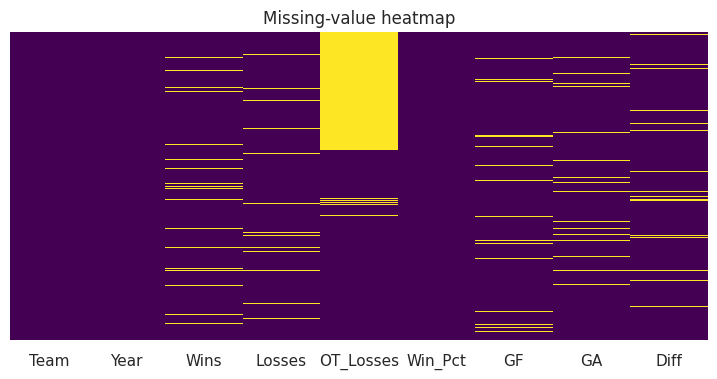

In [183]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing-value heatmap")
plt.show()

### Cell 31 - Duplicate rows
A team can appear only once per year. We check both fully identical rows and repeated (Team, Year) pairs.

In [184]:
print("Fully duplicated rows      :", df.duplicated().sum())
print("Duplicate (Team, Year) keys:", df.duplicated(subset=["Team", "Year"]).sum())

Fully duplicated rows      : 0
Duplicate (Team, Year) keys: 0


### Cell 32 - Remove duplicates

In [185]:
before = len(df)
df = df.drop_duplicates(subset=["Team", "Year"]).reset_index(drop=True)
print(f"Removed {before - len(df)} rows -> {len(df)} remain")

Removed 0 rows -> 582 remain


### Cell 33 - Imputation strategy (for EDA only)
**Decision:** for exploration we fill numeric gaps with the **median** (robust to outliers). This `df_eda` copy is *only* for plots and summaries.

> **Important (leakage):** the train/test files we save later are **not** imputed here. Imputation for modelling happens inside the sklearn pipeline and is fitted on the training set only.

In [186]:
df_eda = df.copy()
num_cols = ["Wins", "Losses", "OT_Losses", "Win_Pct", "GF", "GA", "Diff"]
for col in num_cols:
    df_eda[col] = df_eda[col].fillna(df_eda[col].median())

print("Missing after EDA imputation:", int(df_eda.isna().sum().sum()))

Missing after EDA imputation: 0


##  EDA part 2: distributions and skewness

### Cells 34-38 : Histograms, boxplots, skewness, log1p

### Cell 34 : Histograms

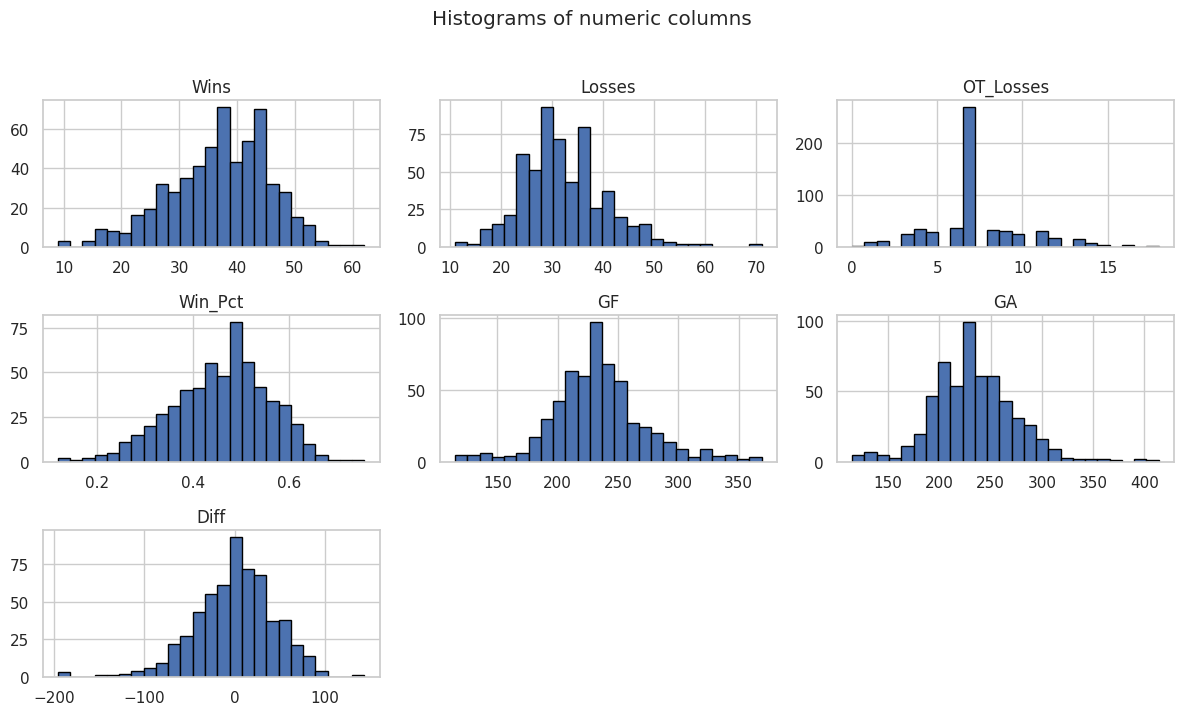

In [187]:
plot_cols = ["Wins", "Losses", "OT_Losses", "Win_Pct", "GF", "GA", "Diff"]
df_eda[plot_cols].hist(bins=25, figsize=(12, 7), edgecolor="black")
plt.suptitle("Histograms of numeric columns", y=1.02)
plt.tight_layout()
plt.show()

### Cell 35 - Boxplots

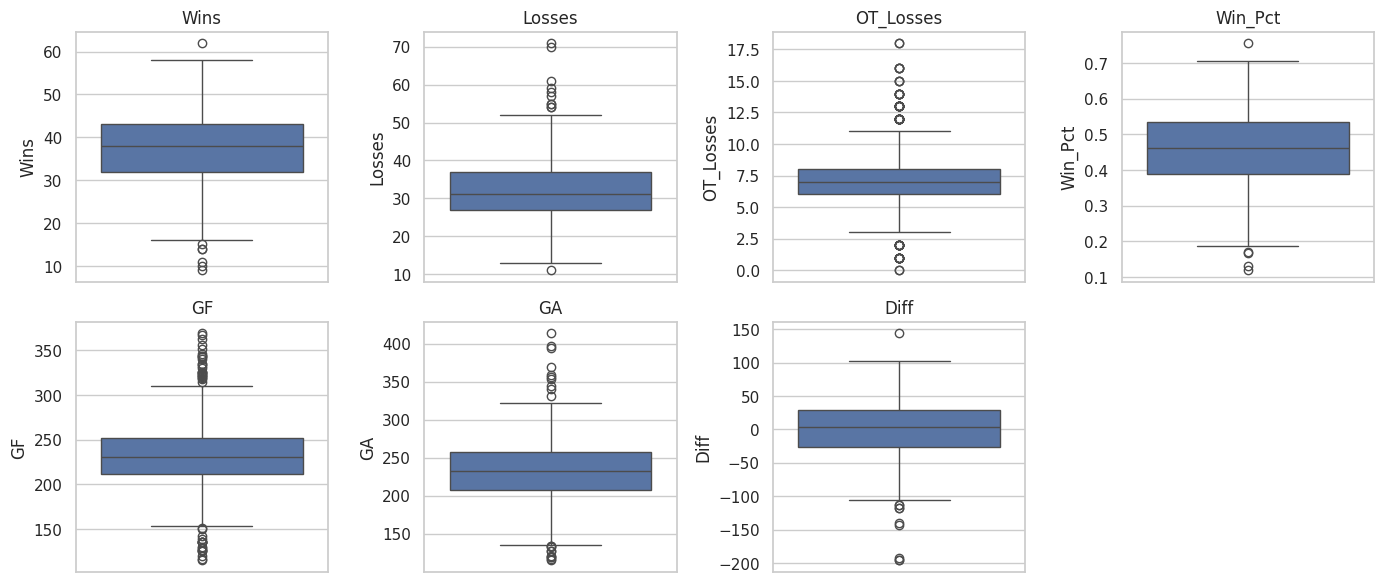

In [188]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(y=df_eda[col], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### Cell 36 : Skewness table
 |skew| < 0.5 is roughly symmetric, 0.5-1 moderately skewed, > 1 highly skewed.

In [189]:
skew = df_eda[plot_cols].skew().round(3).to_frame("skewness")
skew["interpretation"] = pd.cut(skew["skewness"].abs(), [-0.01, 0.5, 1, np.inf],
                                labels=["roughly symmetric", "moderate", "high"])
skew

,skewness,interpretation
Wins,-0.440,roughly symmetric
Losses,0.731,moderate
OT_Losses,0.556,moderate
Win_Pct,-0.314,roughly symmetric
GF,0.270,roughly symmetric
GA,0.345,roughly symmetric
Diff,-0.610,moderate


### Cell 37 - `log1p` check
We test whether np.log1p (log of 1+x, safe for zeros) reduces skewness for the most skewed *non-negative* columns.

In [190]:
candidates = ["OT_Losses", "Losses", "Wins", "GF", "GA"]
cmp = pd.DataFrame({
    "skew_before": df_eda[candidates].skew(),
    "skew_after_log1p": np.log1p(df_eda[candidates]).skew(),
}).round(3)
cmp

,skew_before,skew_after_log1p
OT_Losses,0.556,-1.401
Losses,0.731,-0.249
Wins,-0.440,-1.325
GF,0.270,-0.659
GA,0.345,-0.566


### Cell 38 - Transformation decision
 A transformation is only worth keeping if it clearly lowers skewness **and** the column is non-negative. Tree-based models do not need it, so we apply it only where it helps linear models.

### Cells 39-43 - Before/after plot, scatter plots, yearly trend, conclusion

### Cell 39 - Before/after plot for the chosen column

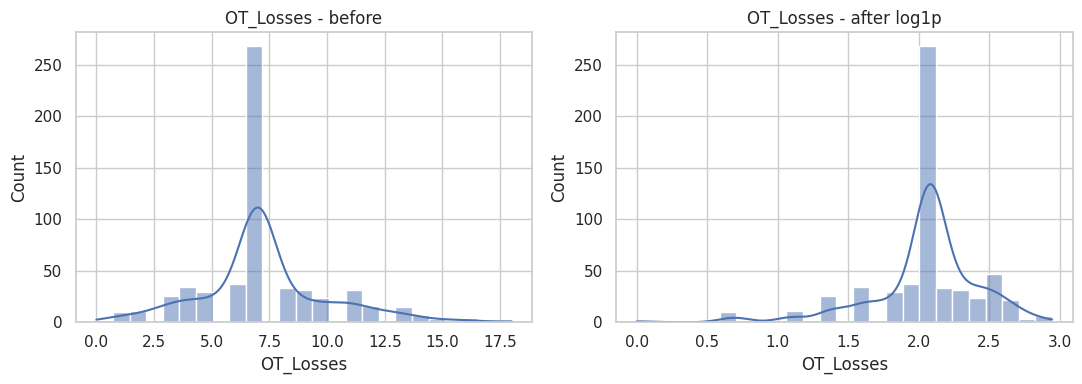

In [191]:
col = "OT_Losses"   # change to the column you decided on in cell 38
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_eda[col], bins=25, kde=True, ax=ax[0]).set_title(f"{col} - before")
sns.histplot(np.log1p(df_eda[col]), bins=25, kde=True, ax=ax[1]).set_title(f"{col} - after log1p")
plt.tight_layout()
plt.show()

### Cell 40 - Scatter plots: what drives winning?

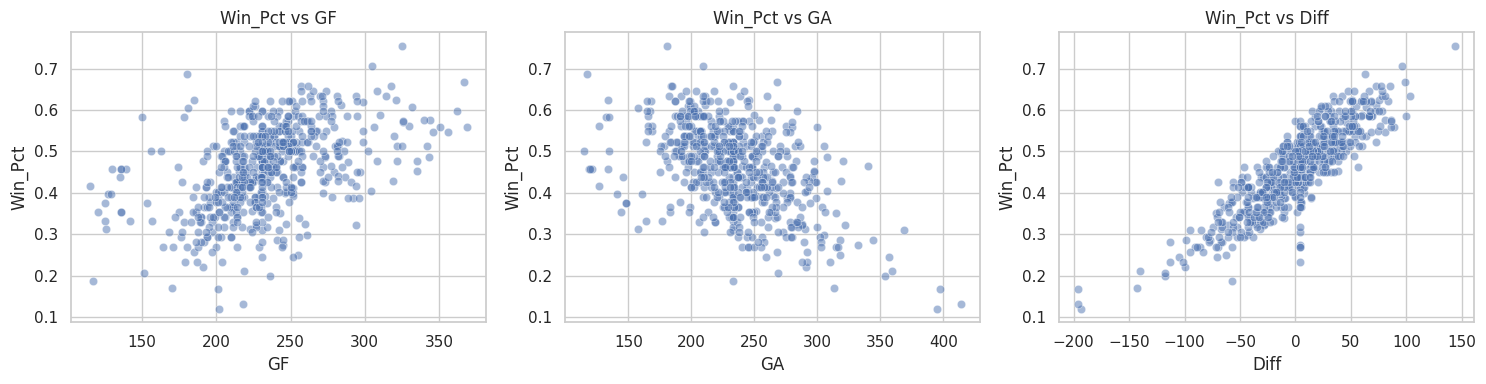

In [192]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, x in zip(ax, ["GF", "GA", "Diff"]):
    sns.scatterplot(data=df_eda, x=x, y="Win_Pct", alpha=0.5, ax=a)
    a.set_title(f"Win_Pct vs {x}")
plt.tight_layout()
plt.show()

### Cell 41 - Correlation heatmap

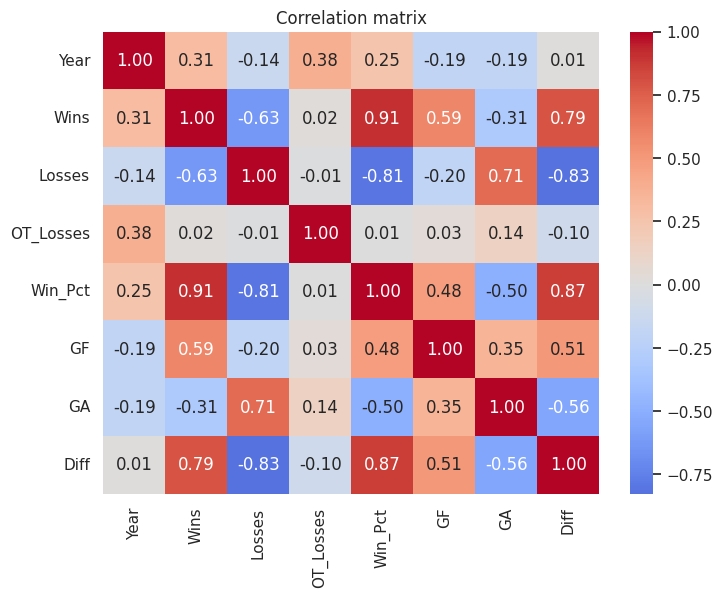

In [193]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_eda[["Year"] + plot_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

### Cell 42 - Yearly trend
Average goals scored per team over the years - did the game change?

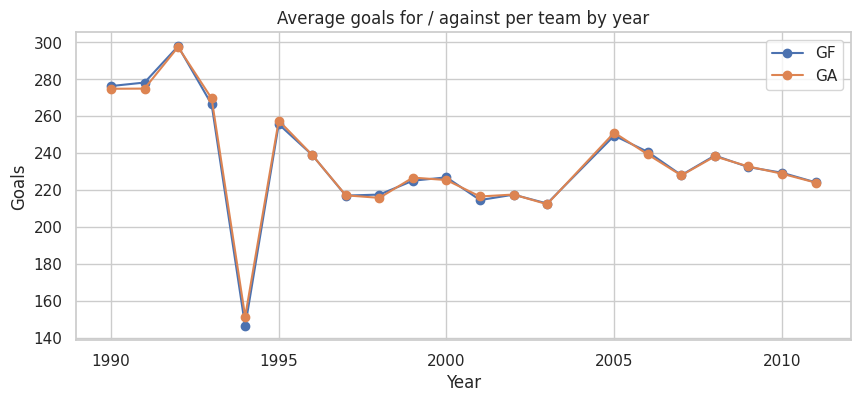

In [194]:
yearly = df_eda.groupby("Year")[["GF", "GA", "Win_Pct"]].mean()
yearly[["GF", "GA"]].plot(figsize=(10, 4), marker="o")
plt.title("Average goals for / against per team by year")
plt.ylabel("Goals")
plt.show()

## Outliers, target creation, chronological split

### Cells 44-48 - IQR outliers and decision table

### Cell 44 - IQR function

In [195]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

### Cell 45 - Count outliers in each column

In [196]:
rows = []
for col in ["Wins", "Losses", "OT_Losses", "Win_Pct", "GF", "GA", "Diff"]:
    lo, hi = iqr_bounds(df_eda[col])
    n_out = int(((df_eda[col] < lo) | (df_eda[col] > hi)).sum())
    rows.append({"column": col, "lower": round(lo, 2), "upper": round(hi, 2),
                 "n_outliers": n_out, "pct": round(100 * n_out / len(df_eda), 2)})
outlier_table = pd.DataFrame(rows)
outlier_table

,column,lower,upper,n_outliers,pct
0,Wins,15.50,59.50,7,1.20
1,Losses,12.00,52.00,11,1.89
2,OT_Losses,3.00,11.00,70,12.03
3,Win_Pct,0.17,0.75,5,0.86
4,GF,152.00,312.00,43,7.39
5,GA,134.50,330.50,20,3.44
6,Diff,-109.62,113.38,10,1.72


### Cell 46 - Inspect the extreme rows
Before removing anything, look at *who* the outliers are.

In [197]:
lo, hi = iqr_bounds(df_eda["Diff"])
df_eda[(df_eda["Diff"] < lo) | (df_eda["Diff"] > hi)].sort_values("Diff").head(10)

,Team,Year,Wins,Losses,OT_Losses,Win_Pct,GF,GA,Diff
60,San Jose Sharks,1992,11.0,71.0,7.0,0.131,218.0,414.0,-196.0
82,Ottawa Senators,1993,14.0,61.0,7.0,0.167,201.0,397.0,-196.0
56,Ottawa Senators,1992,10.0,70.0,7.0,0.119,202.0,395.0,-193.0
225,Atlanta Thrashers,1999,14.0,57.0,4.0,0.171,170.0,313.0,-143.0
37,San Jose Sharks,1991,17.0,58.0,7.0,0.212,219.0,359.0,-140.0
15,Quebec Nordiques,1990,16.0,50.0,7.0,0.200,236.0,354.0,-118.0
193,Tampa Bay Lightning,1997,17.0,55.0,7.0,0.207,151.0,269.0,-118.0
220,Tampa Bay Lightning,1998,19.0,54.0,7.0,0.232,179.0,292.0,-113.0
365,Pittsburgh Penguins,2003,23.0,31.0,4.0,0.280,190.0,303.0,-113.0
126,Detroit Red Wings,1995,62.0,13.0,7.0,0.756,325.0,181.0,144.0


### Cell 47 - Decision table
Here an outlier is usually a **real** performance (e.g. a dominant team or a lockout-shortened season), not a data error, so removing it would delete real information.

In [198]:
decision = outlier_table[["column", "n_outliers"]].copy()
decision["decision"] = "Keep"
decision["reason"] = "Real team-season performance, not a recording error; tree models are robust to it"
decision

,column,n_outliers,decision,reason
0,Wins,7,Keep,"Real team-season performance, not a recording ..."
1,Losses,11,Keep,"Real team-season performance, not a recording ..."
2,OT_Losses,70,Keep,"Real team-season performance, not a recording ..."
3,Win_Pct,5,Keep,"Real team-season performance, not a recording ..."
4,GF,43,Keep,"Real team-season performance, not a recording ..."
5,GA,20,Keep,"Real team-season performance, not a recording ..."
6,Diff,10,Keep,"Real team-season performance, not a recording ..."


### Cells 49-54 - Target, class balance, chronological split, save *

### Cell 49 - Create the classification target Team_Status
A team is **Winning** (1) if Win_Pct >= 0.5, otherwise **Losing** (0).Win_Pct is complete (never blanked), so the target is always defined.

In [199]:
df["Team_Status"] = (df["Win_Pct"] >= 0.5).astype(int)
df["Team_Status"].value_counts()

,count
Team_Status,
0,350
1,232


### Cell 50 - Class balance

,count,percent
Team_Status,,
0,350,60.14
1,232,39.86


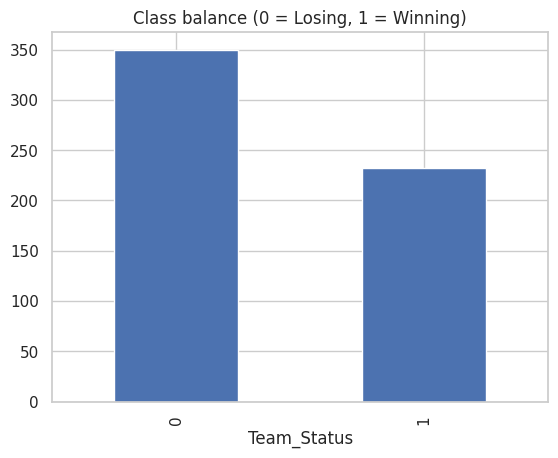

In [200]:
balance = df["Team_Status"].value_counts().to_frame("count")
balance["percent"] = (balance["count"] / len(df) * 100).round(2)
display(balance)
df["Team_Status"].value_counts().plot(kind="bar", title="Class balance (0 = Losing, 1 = Winning)")
plt.show()

### Cell 51 - Chronological split (80/20 by Year)
We predict the **future from the past**, so rows are sorted by `Year` and the earliest ~80% go to train. A random split would leak future information into training.

In [201]:
df_sorted = df.sort_values("Year", kind="stable").reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)
cutoff_year = df_sorted.loc[split_idx, "Year"]

train = df_sorted[df_sorted["Year"] < cutoff_year].copy()
test = df_sorted[df_sorted["Year"] >= cutoff_year].copy()
print("Cutoff year:", cutoff_year)
print("Train:", train.shape, "| Years", train["Year"].min(), "-", train["Year"].max())
print("Test :", test.shape, "| Years", test["Year"].min(), "-", test["Year"].max())

Cutoff year: 2008
Train: (462, 10) | Years 1990 - 2007
Test : (120, 10) | Years 2008 - 2011


### Cell 52 - Check the split
No year may appear in both sets, and class balance should be similar in both.

In [202]:
print("Overlapping years:", set(train["Year"]) & set(test["Year"]))
pd.DataFrame({
    "train_%": train["Team_Status"].value_counts(normalize=True) * 100,
    "test_%": test["Team_Status"].value_counts(normalize=True) * 100,
}).round(2)

Overlapping years: set()


,train_%,test_%
Team_Status,,
0,64.07,45.0
1,35.93,55.0


### Cell 53 - Save `train.csv` and `test.csv`
These keep the missing values (imputation happens later inside the pipeline, fitted on train only).

In [203]:
train.to_csv("train.csv", index=False)
test.to_csv("test.csv", index=False)
print("Saved train.csv and test.csv")

Saved train.csv and test.csv


### Cell 54 - Final check

In [204]:
print(pd.read_csv("train.csv").shape, pd.read_csv("test.csv").shape)
print("Missing values left in train:", int(pd.read_csv("train.csv").isna().sum().sum()))

(462, 10) (120, 10)
Missing values left in train: 364


## Summary
- Inspected data, reported and visualised missing values, removed duplicates.
- Studied distributions and skewness; decided on transformations.
- Kept IQR outliers as real performances.
- Created `Team_Status`, checked class balance, split chronologically and saved `train.csv` / `test.csv`.
